### E 步骤

对于每个 $(n,k)$，计算下面的值。

$$
q^{(n)}(k) = \frac{\phi_k \mathcal{N}(\boldsymbol{x}^{(n)}; \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)}{\sum_{j=1}^{K} \phi_j \mathcal{N}(\boldsymbol{x}^{(n)}; \boldsymbol{\mu}_j, \boldsymbol{\Sigma}_j)}
$$

### M 步骤

对于每个 $k$，计算下面的值。

$$
\phi_k = \frac{1}{N} \sum_{n=1}^{N} q^{(n)}(k)
$$

$$
\boldsymbol{\mu}_k = \frac{\sum_{n=1}^{N} q^{(n)}(k) \boldsymbol{x}^{(n)}}{\sum_{n=1}^{N} q^{(n)}(k)}
$$

$$
\boldsymbol{\Sigma}_k = \frac{\sum_{n=1}^{N} q^{(n)}(k) (\boldsymbol{x}^{(n)} - \boldsymbol{\mu}_k)(\boldsymbol{x}^{(n)} - \boldsymbol{\mu}_k)^\mathrm{T}}{\sum_{n=1}^{N} q^{(n)}(k)}
$$

### 终止判断

计算下一个对数似然，并将其与上一个对数似然进行比较。

$$
\frac{1}{N} \sum_{n=1}^{N} \log \sum_{j=1}^{K} \phi_j \mathcal{N}(\boldsymbol{x}^{(n)}; \boldsymbol{\mu}_j, \boldsymbol{\Sigma}_j)
$$


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt


In [2]:
xs = np.loadtxt('./data/old_faithful.txt')
print(xs.shape) # (272, 2)

(272, 2)


In [3]:
xs.mean(axis=0)

array([ 3.48778309, 70.89705882])

In [4]:
# initialize parameters
phis = np.array([0.5, 0.5])
mus = np.array([[0.0, 50.0], [0.0, 100.0]])
covs = np.array([np.eye(2), np.eye(2)])

In [5]:
K = len(phis)  # 2
N = len(xs)  # 272
MAX_ITERS = 100
THRESHOLD = 1e-4

$$
\mathcal{N}(\boldsymbol{x} | \boldsymbol{\mu}, \boldsymbol{\Sigma}) = \frac{1}{\sqrt{(2\pi)^d |\boldsymbol{\Sigma}|}} \exp\left(-\frac{1}{2} (\boldsymbol{x} - \boldsymbol{\mu})^\mathrm{T} \boldsymbol{\Sigma}^{-1} (\boldsymbol{x} - \boldsymbol{\mu})\right)
$$

In [6]:
# single data point
# **多维正态分布（Multivariate Normal Distribution）在给定点 x 处的概率密度函数（Probability Density Function, PDF）**的值。
def multivariate_normal(x, mu, cov):
    det = np.linalg.det(cov)
    inv = np.linalg.inv(cov)
    d = len(x)
    z = 1 / np.sqrt((2 * np.pi) ** d * det)
    y = z * np.exp((x - mu).T @ inv @ (x - mu) / -2.0)
    return y

$$
p(\boldsymbol{x} | \boldsymbol{\phi}, \boldsymbol{\mu}, \boldsymbol{\Sigma}) = \sum_{k=1}^{K} \phi_k \mathcal{N}(\boldsymbol{x} | \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)
$$

In [7]:
def gmm(x, phis, mus, covs):
    K = len(phis)
    y = 0
    for k in range(K):
        phi, mu, cov = phis[k], mus[k], covs[k]
        y += phi * multivariate_normal(x, mu, cov)
    return y

$$
\mathcal{L}_{\text{avg}} = \frac{1}{N} \sum_{n=1}^{N} \log \left( \sum_{k=1}^{K} \phi_k \mathcal{N}(\boldsymbol{x}^{(n)} | \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k) \right)
$$

In [8]:
def likelihood(xs, phis, mus, covs):
    """ log likelihood """
    eps = 1e-8
    L = 0
    N = len(xs)
    # sum n
    for x in xs:
        # sum k
        y = gmm(x, phis, mus, covs)
        L += np.log(y + eps)
    return L / N

In [9]:
current_likelihood = likelihood(xs, phis, mus, covs)
current_likelihood

np.float64(-16.538249470807674)

In [10]:
for n_iter in range(MAX_ITERS):
    
    # e-step
    qs = np.zeros((N, K))
    for n in range(N):
        x = xs[n]
        for k in range(K):
            phi, mu, cov = phis[k], mus[k], covs[k]
            qs[n][k] = phi * multivariate_normal(x, mu, cov)
        # 等价于
        # qs[n] /= qs[n].sum()
        qs[n] /= gmm(x, phis, mus, covs)

    # m-step
    qs_sum = qs.sum(axis=0)
    for k in range(K):
        # phis
        phis[k] = qs_sum[k] / N
        
        # mus
        c = 0
        for n in range(N):
            c += qs[n, k] * xs[n]
        mus[k] = c / qs_sum[k]

        # covs
        c = 0
        for n in range(N):
            z = xs[n] - mus[k]
            z = z[:, np.newaxis]
            c += qs[n, k] * z @ z.T
        covs[k] = c / qs_sum[k]

    print(f'{current_likelihood:.3f}')
    next_likelihood = likelihood(xs, phis, mus, covs)
    diff = np.abs(next_likelihood - current_likelihood)
    if diff < THRESHOLD:
        print('convergence')
        break
    current_likelihood = next_likelihood

-16.538
-4.415
-4.357
-4.302
-4.245
-4.200
-4.164
-4.156
-4.155
convergence


Text(0, 0.5, 'Waiting(Min)')

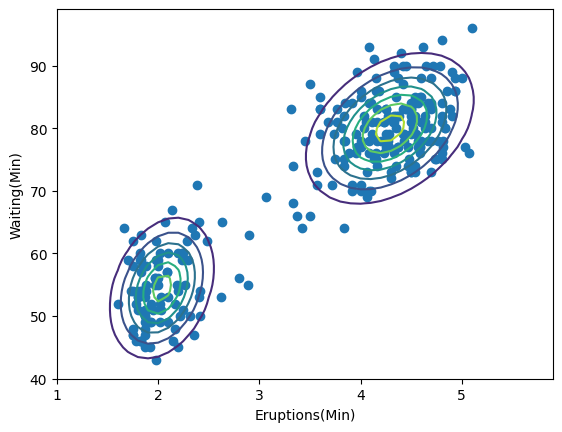

In [11]:
def plot_contour(w, mus, covs):
    x = np.arange(1, 6, 0.1)
    y = np.arange(40, 100, 1)
    X, Y = np.meshgrid(x, y)
    Z = np.zeros_like(X)

    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            x = np.array([X[i, j], Y[i, j]])

            for k in range(len(mus)):
                mu, cov = mus[k], covs[k]
                Z[i, j] += w[k] * multivariate_normal(x, mu, cov)
    # print(Z.shape)
    plt.contour(X, Y, Z)

plt.scatter(xs[:,0], xs[:,1])
plot_contour(phis, mus, covs)
plt.xlabel('Eruptions(Min)')
plt.ylabel('Waiting(Min)')

In [12]:
phis, mus, covs

(array([0.35595101, 0.64404899]),
 array([[ 2.03657905, 54.48044568],
        [ 4.28983008, 79.97014211]]),
 array([[[ 0.06931941,  0.43676263],
         [ 0.43676263, 33.70834056]],
 
        [[ 0.16975533,  0.93790633],
         [ 0.93790633, 36.01589174]]]))

In [14]:
# genearte data
N = 500
new_xs = np.zeros((N, 2))
for n in range(N):
    k = np.random.choice(2, p=phis)
    mu, cov = mus[k], covs[k]
    new_xs[n] = np.random.multivariate_normal(mu, cov)

Text(0, 0.5, 'Waiting(Min)')

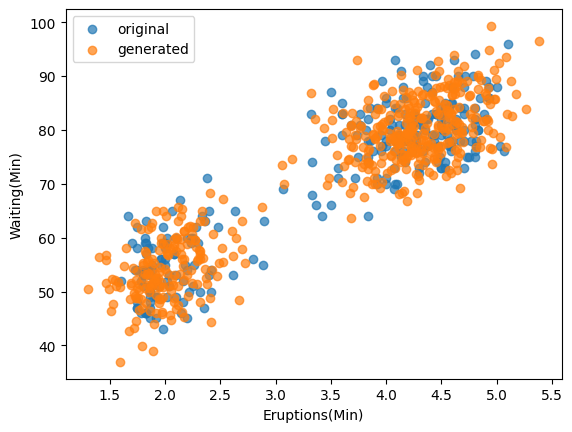

In [15]:
plt.scatter(xs[:,0], xs[:,1], alpha=0.7, label='original')
plt.scatter(new_xs[:,0], new_xs[:,1], alpha=0.7, label='generated')
plt.legend()
plt.xlabel('Eruptions(Min)')
plt.ylabel('Waiting(Min)')